# 22. 상대적 수요 유지 순위모형: 로그 연면적 추가

기존4변수에 **log(1+2024년 건축물 연면적[천㎡])**만 추가한5변수를 비교한다.

입력: 개통 전 권역 내 수요 비중(%), log(1+개통 전 승차인원), GTX역 보행시간(분, 로그 없음), 경쟁 목적지 비율(%), log(1+연면적[천㎡]).

학습 목표는 권역 전체보다 상대적으로 수요가 잘 유지된 격자를 높은 순위에 놓는 것이다. 변화율 크기 자체를 맞히거나 확률을 내는 모형이 아니다.

- 같은126개, 기존 쌍대비교 생성·쌍 차이 표준화·L2 로지스틱 유지.
- 두 권역 학습/한 권역 외부검증. 학습권역 내부 LOSO의 평균AUC로 C를 선택한다.
- 입력5개 결측·무한값 여부를 검사하고, 공통126개에서 비교한다. 이번 자료에 결측이 없어 임의 대체하지 않는다.
- 외부 결과로 C나 변수 조합을 추가 조정하지 않는다. 동일 자료의 반복 탐색이므로 후보 비교 후 성능을 최종 일반화 성능으로 확정하지 않는다.
- 상위10·20·30%는 기존 평가범위를 유지한다. 실제Y는 사후 진단에만 사용한다.
- 원래4변수 코드/모델 파일은 수정하지 않는다. CSV·그림·모델 파일 자동 저장 없음.

In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

from pathlib import Path
import importlib.util
import pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
paths=[*sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir()), Path.cwd(),Path.cwd()/'analysis',Path.cwd()/'gtx_a_bus_analysis'/'analysis',Path.cwd()/'github_2026-UROP'/'gtx_a_bus_analysis'/'analysis']
ANALYSIS=next((p for p in paths if (p/'22_쌍대순위_로그연면적추가_비교.py').exists()),None)
if ANALYSIS is None:raise FileNotFoundError('프로젝트 또는 analysis 폴더에서 실행하세요.')
spec=importlib.util.spec_from_file_location('floor_rank',next((UROP_ROOT / 'code').rglob('22_쌍대순위_로그연면적추가_비교.py')))
experiment=importlib.util.module_from_spec(spec);spec.loader.exec_module(experiment)
fonts={f.name for f in font_manager.fontManager.ttflist}
font=next((f for f in ['AppleGothic','Apple SD Gothic Neo','NanumGothic','Malgun Gothic','Noto Sans CJK KR'] if f in fonts),None)
if font:plt.rcParams['font.family']=font
plt.rcParams.update({'axes.unicode_minus':False,'figure.dpi':110,'font.size':11})
pd.set_option('display.max_columns',25)
oof,folds,overall,tops=experiment.evaluate()
display(overall.round(4))
display(folds.round(4))

,모형,역평균AUC,격자수가중AUC,전체쌍PairwiseLoss,상위27적중수,상위27Precision,상위Y중앙값,상위기초20미만수
0,기존4변수,0.7311,0.7404,0.5385,22,0.8148,15.7964,22
1,로그연면적추가5변수,0.7402,0.7505,0.5439,22,0.8148,15.7964,22


,모형,검증역,n,선택C,내부AUC,AUC,PairwiseLoss,외부비교쌍수,상위20수,상위20적중수,Precision20,Lift20,상위Y중앙값,상위Y가중평균,상위기초20미만수
0,기존4변수,대곡,37,31.6228,0.7481,0.6842,0.6085,342,8,6,0.7500,1.5417,13.5237,9.9689,7
1,기존4변수,운정중앙,63,0.1000,0.6820,0.7769,0.5126,986,13,11,0.8462,1.5679,37.2259,39.1639,13
2,기존4변수,킨텍스,26,0.3162,0.7262,0.7321,0.5477,168,6,5,0.8333,1.5476,1.9140,1.3872,2
3,로그연면적추가5변수,대곡,37,100.0000,0.7413,0.7105,0.5832,342,8,6,0.7500,1.5417,13.5237,9.9851,7
4,로그연면적추가5변수,운정중앙,63,0.0316,0.6895,0.7840,0.5211,986,13,11,0.8462,1.5679,30.5592,33.4458,13
5,로그연면적추가5변수,킨텍스,26,0.3162,0.7481,0.7262,0.5982,168,6,5,0.8333,1.5476,4.0024,1.5141,2


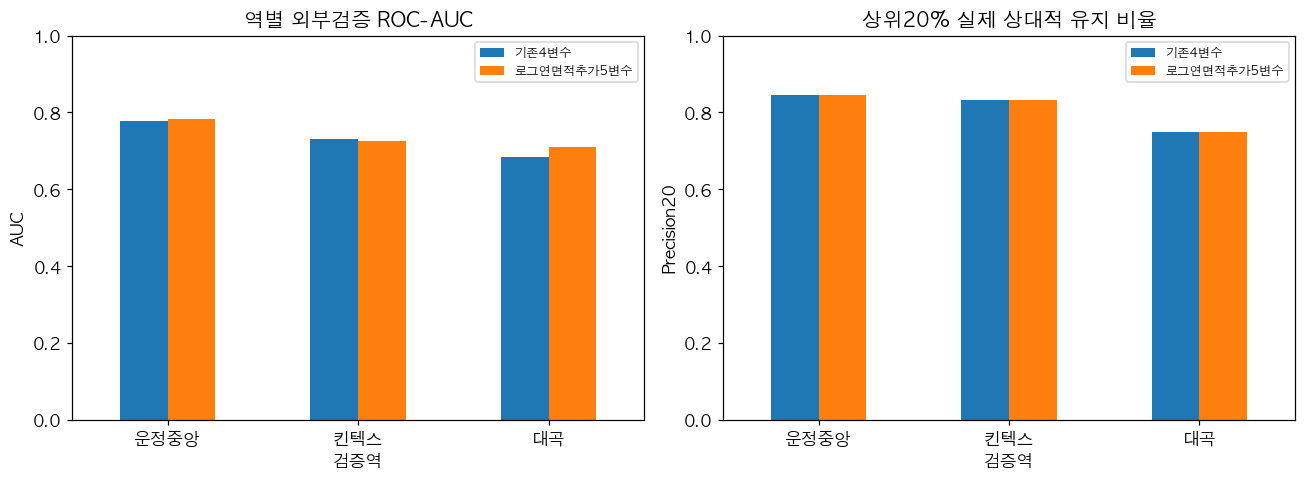

,모형,검증역,상위비율,K,적중수,Precision,Lift,실제Y중앙값
0,기존4변수,대곡,0.1,4,2,0.5000,1.0278,27.9176
1,기존4변수,대곡,0.2,8,6,0.7500,1.5417,13.5237
2,기존4변수,대곡,0.3,12,9,0.7500,1.5417,11.2510
3,기존4변수,운정중앙,0.1,7,7,1.0000,1.8529,37.2259
4,기존4변수,운정중앙,0.2,13,11,0.8462,1.5679,37.2259
5,기존4변수,운정중앙,0.3,19,16,0.8421,1.5604,20.5592
6,기존4변수,킨텍스,0.1,3,2,0.6667,1.2381,0.2829
7,기존4변수,킨텍스,0.2,6,5,0.8333,1.5476,1.9140
8,기존4변수,킨텍스,0.3,8,6,0.7500,1.3929,1.9140
9,로그연면적추가5변수,대곡,0.1,4,2,0.5000,1.0278,27.9176


In [2]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,metric,title in [(axes[0],'AUC','역별 외부검증 ROC-AUC'),(axes[1],'Precision20','상위20% 실제 상대적 유지 비율')]:
 folds.pivot(index='검증역',columns='모형',values=metric).reindex(['운정중앙','킨텍스','대곡']).plot.bar(ax=ax)
 ax.set(xlabel='검증역',ylabel=metric,title=title,ylim=(0,1));ax.tick_params(axis='x',rotation=0)
 ax.legend(fontsize=8)
plt.tight_layout();plt.show()
display(tops.round(4))

## 5변수 모형의 상위 격자

선정된 격자가 기존4변수와 완전히 같다는 뜻은 아니다. 같은 적중수·전체중앙값이 나와도 개별 격자와 순서는 달라질 수 있다. 권역 간 점수의 절댓값을 비교하지 않는다.

In [3]:
five=oof[(oof['모형']=='로그연면적추가5변수')&oof['상위20']].sort_values(['nearest_station','순위'])
with pd.option_context('display.max_rows',40):
 display(five[['nearest_station','셀 ID','순위','board_2024_all','board_2025_all','2024년 건축물 연면적(천㎡)','log1p_floor_area','Y','점수']].round(4))
rows=[]
for station,g in oof.groupby('nearest_station',sort=False):
 a=set(g[(g['모형']=='기존4변수')&g['상위20']]['셀 ID'])
 b=set(g[(g['모형']=='로그연면적추가5변수')&g['상위20']]['셀 ID'])
 rows.append({'권역':station,'새로선정':sorted(b-a),'선정제외':sorted(a-b)})
display(pd.DataFrame(rows))

,nearest_station,셀 ID,순위,board_2024_all,board_2025_all,2024년 건축물 연면적(천㎡),log1p_floor_area,Y,점수
160,대곡,14004,1,1.0,4.0,0.2025,0.1844,361.2510,0.5910
131,대곡,1962,2,4.0,4.0,8.7694,2.2793,61.2510,-0.0977
128,대곡,1518,3,3.0,1.0,0.1630,0.1510,-5.4157,-0.3410
147,대곡,9285,4,3.0,1.0,1.9276,1.0742,-5.4157,-0.3539
161,대곡,14284,5,12.0,6.0,11.7930,2.5489,11.2510,-0.5851
141,대곡,7368,6,3.0,3.0,0.3699,0.3148,61.2510,-0.6778
153,대곡,12461,7,595.0,283.0,8.9451,2.2971,8.8140,-0.7123
143,대곡,7608,8,11.0,6.0,0.7013,0.5314,15.7964,-0.7244
185,운정중앙,7262,1,1.0,2.0,0.4079,0.3421,170.5592,0.1385
197,운정중앙,9893,2,3.0,1.0,0.2115,0.1918,3.8926,0.1067


,권역,새로선정,선정제외
0,대곡,[14284],[8805]
1,운정중앙,[10101],[7883]
2,킨텍스,[11506],[9815]


## 이번 비교 결과

| 지표 | 기존4변수 | 로그연면적 추가5변수 |
|---|---:|---:|
| 역별 AUC 평균 | 0.7311 | 0.7402 |
| 전체 외부 비교쌍 손실 | 0.5385 | 0.5439 |
| 상위27개 실제 상대적 유지 | 22개 | 22개 |
| 상위27개 실제Y 중앙값 | +15.80%p | +15.80%p |

대곡 AUC .684→.711, 운정중앙 .777→.784, 킨텍스 .732→.726이다. 전체 순위 구별 지표는 소폭 개선됐지만 킨텍스는 약간 감소했고 손실도 소폭 커졌다. 상위20% 적중률은 세 역 모두 기존과 같다.

따라서 연면적을 포함한5변수 후보를 구축했으나, 기존보다 전반적으로 우수하다고 확정할 결과는 아니다. 연면적의 p값이나 인과효과를 평가한 분석도 아니다. GTX-C 적용은 아직 수행하지 않았으며 이 비교로 최종모형·최종 일반화 성능을 확정하지 않는다.